# D-T model

In [1]:
import openmc
import numpy as np
import math
import matplotlib.pyplot as plt
from fusion_fuel_concepts_explorer.sources import SteadyStateSource

 =================>     STOCHASTIC VOLUME CALCULATION     <=================

 Running volume calculation 1 \
   Cell 50: 337409.3393721693 +/- 3373.7533999453817 cm^3 \
   Cell 51: 2990501.9522099015 +/- 10043.9412420218 cm^3 \
   Cell 52: 4881775.417772919 +/- 12832.731718500425 cm^3 \
   Cell 1: 215913716248.00873 +/- 53940.24021966374 cm^3

In [2]:
avg_density_DT = 1.3e20
avg_temperature_DT = 14.0
density_peaking_DT = 1.168
temperature_peaking_DT = 1.83
density_profile_DT = lambda rho: avg_density_DT * density_peaking_DT * ((1.0 - rho**2.0) ** (density_peaking_DT - 1.0))
temperature_profile_DT = lambda rho: avg_temperature_DT * temperature_peaking_DT * ((1.0 - rho**2.0) ** (temperature_peaking_DT - 1.0))

DT_source = SteadyStateSource(
    source_type="DT",
    volume_m3=150.0,
    n_i=density_profile_DT,
    T_i=temperature_profile_DT,
    tau_p=2.5,
)

number_of_neutrons_per_second = DT_source.reaction_rates_s['DT'] + DT_source.reaction_rates_s['DDn'] + DT_source.reaction_rates_s['TT'] + DT_source.reaction_rates_s['THe3_np']
print("Number of neutrons per second", number_of_neutrons_per_second, '\n')
eV_to_Jouls = 1.60218e-19

# Volume (to be calculated)
tf_coil_magnet_volume = 337409.34 # * 18 if reflective BC.. TBV
tf_coil_insulation_volume = 2990501.95 # * 18
tf_coil_case_volume = 4881775.41 # * 18
ybco_volume = 0.01 * tf_coil_magnet_volume # about 1% of the total (literature), according to the definition in OpenMC it would be 0.72%

Number of neutrons per second 1.8508581069096337e+20 



## TBR

In [3]:
sp = openmc.StatePoint("statepoint.1000.h5")

tbr = sp.get_tally(name='TBR_total')
df_tbr = tbr.get_pandas_dataframe()
tbr_mean = df_tbr["mean"].sum()
tbr_std = (df_tbr["std. dev."]**2).sum()**0.5
print(f"The reactor has a TBR of {tbr_mean:.4f} ± {tbr_std:.4f} ({100*tbr_std/tbr_mean:.2f} %)\n")

The reactor has a TBR of 1.0865 ± 0.0088 (0.81 %)



In [4]:
tbr_channel = sp.get_tally(name='TBR_channel')
df_tbr_c = tbr_channel.get_pandas_dataframe()
tbr_c_mean = df_tbr_c["mean"].sum()
tbr_c_std = (df_tbr_c["std. dev."]**2).sum()**0.5
print(f"The Channel has a TBR of {tbr_c_mean:.4f} ± {tbr_c_std:.4f}")

tbr_breeder = sp.get_tally(name='TBR_breeder')
df_tbr_breeder = tbr_breeder.get_pandas_dataframe()
tbr_breeder_mean = df_tbr_breeder["mean"].sum()
tbr_breeder_std = (df_tbr_breeder["std. dev."]**2).sum()**0.5
print(f"The Breeder has a TBR of {tbr_breeder_mean:.4f} ± {tbr_breeder_std:.4f}")

print(f"Sum of contributions = {tbr_c_mean+tbr_breeder_mean:.4f}")

The Channel has a TBR of 0.2415 ± 0.0022
The Breeder has a TBR of 0.8432 ± 0.0081
Sum of contributions = 1.0847


## Power deposition

In [5]:
def compute_power_and_density(name, volume):
    """
    Compute deposited power (MW) and power density (MW/m^3)
    from an OpenMC tally, including statistical uncertainty (1σ).

    Parameters
    ----------
    name : str
        Name of the tally to extract (e.g., "heating_full").
    volume : float
        Volume of the region in m^3.

    Returns
    -------
    h_MW : float
        Total deposited power in MW.
    h_std_MW : float
        Standard deviation of deposited power (MW).
    pd_MW_m3 : float
        Power density in MW/m^3.
    pd_std_MW_m3 : float
        Standard deviation of power density (MW/m^3).
    """

    # Extract the tally
    tally = sp.get_tally(name=name)

    # Mean and standard deviation arrays
    mean_vals = tally.mean.flatten()
    std_vals  = tally.std_dev.flatten()

    # Sum of means
    total_mean = mean_vals.sum()

    # Propagated std dev (quadrature)
    total_std = (std_vals**2).sum()**0.5

    # Convert to MW
    h_MW = eV_to_Jouls * number_of_neutrons_per_second * total_mean / 1e6
    h_std_MW = eV_to_Jouls * number_of_neutrons_per_second * total_std / 1e6

    # Power density
    pd_MW_m3 = h_MW / volume
    pd_std_MW_m3 = h_std_MW / volume

    # Relative error
    rel_err = h_std_MW / h_MW if h_MW != 0 else 0.0

    # Print results
    print(f"Results for tally '{name}':")
    print(f"Power deposited: {h_MW:.3f} ± {h_std_MW:.3f} MW "
          f"({100*rel_err:.2f} %)")
    print(f"Power density:   {pd_MW_m3:.3f} ± {pd_std_MW_m3:.3f} MW/m^3\n")

    return h_MW, h_std_MW, pd_MW_m3, pd_std_MW_m3

In [6]:
h_tf_coil_magnet, h_std_tf_coil_magnet, pd_tf_coil_magnet, pd_std_tf_coil_magnet = compute_power_and_density("q_vol_tf_coil_magnet", tf_coil_magnet_volume)
h_tf_coil_insulation, h_std_tf_coil_insulation, pd_tf_coil_insulation, pd_std_tf_coil_insulation = compute_power_and_density("q_vol_tf_coil_insulation", tf_coil_insulation_volume)
h_tf_coil_case, h_std_tf_coil_case, pd_tf_coil_case, pd_std_tf_coil_case = compute_power_and_density("q_vol_tf_coil_case", tf_coil_case_volume)

Results for tally 'q_vol_tf_coil_magnet':
Power deposited: 0.006 ± 0.000 MW (6.18 %)
Power density:   0.000 ± 0.000 MW/m^3

Results for tally 'q_vol_tf_coil_insulation':
Power deposited: 0.066 ± 0.014 MW (20.95 %)
Power density:   0.000 ± 0.000 MW/m^3

Results for tally 'q_vol_tf_coil_case':
Power deposited: 0.600 ± 0.088 MW (14.70 %)
Power density:   0.000 ± 0.000 MW/m^3



In [7]:
qvol_tot = sp.get_tally(name='heating_full')

# Sum over the mean values
total_mean = qvol_tot.mean.sum()
std_vals  = qvol_tot.std_dev.flatten()
total_std = (std_vals**2).sum()**0.5

# Compute deposited power (in MW)
h_MW = eV_to_Jouls * number_of_neutrons_per_second * total_mean / 1e6
h_std_MW = eV_to_Jouls * number_of_neutrons_per_second * total_std / 1e6

# Print results
print(f"Power deposited on the entire geometry: {h_MW:.3f} ± {h_std_MW:.3f}  MW")

Power deposited on the entire geometry: 469.709 ± 1.454  MW


In [8]:
# q_vol_tf_coil_magnet = sp.get_tally(name='q_vol_tf_coil_magnet')

# total_mean = q_vol_tf_coil_magnet.mean.sum()
# std_vals  = q_vol_tf_coil_magnet.std_dev.flatten()
# total_std = (std_vals**2).sum()**0.5

# h_MW = eV_to_Jouls * number_of_neutrons_per_second * total_mean / 1e6
# h_std_MW = eV_to_Jouls * number_of_neutrons_per_second * total_std / 1e6

# print(f"Power deposited on TF coil magnet: {h_MW:.3f} ± {h_std_MW:.3f}  MW")
# q_vol_tf_coil_insulation = sp.get_tally(name='q_vol_tf_coil_insulation')

# total_mean = q_vol_tf_coil_insulation.mean.sum()
# std_vals  = q_vol_tf_coil_insulation.std_dev.flatten()
# total_std = (std_vals**2).sum()**0.5

# h_MW = eV_to_Jouls * number_of_neutrons_per_second * total_mean / 1e6
# h_std_MW = eV_to_Jouls * number_of_neutrons_per_second * total_std / 1e6

# print(f"Power deposited on TF coil insulation: {h_MW:.3f} ± {h_std_MW:.3f}  MW")
# q_vol_tf_coil_case = sp.get_tally(name='q_vol_tf_coil_case')

# total_mean = q_vol_tf_coil_case.mean.sum()
# std_vals  = q_vol_tf_coil_case.std_dev.flatten()
# total_std = (std_vals**2).sum()**0.5

# h_MW = eV_to_Jouls * number_of_neutrons_per_second * total_mean / 1e6
# h_std_MW = eV_to_Jouls * number_of_neutrons_per_second * total_std / 1e6

# print(f"Power deposited on TF coil insulation: {h_MW:.3f} ± {h_std_MW:.3f}  MW")

## Neutron flux

In [9]:
def plot_flux_spectrum(sp, name, volume, number_of_neutrons_per_second):

    import numpy as np
    import matplotlib.pyplot as plt
    import openmc

    energy_bins = openmc.mgxs.GROUP_STRUCTURES['TRIPOLI-315']
    energy_filter = openmc.EnergyFilter(energy_bins)

    tally = sp.get_tally(name=name)

    # Convert tally results to numpy arrays
    mean = np.asarray(tally.mean)
    std  = np.asarray(tally.std_dev)

    # Determine number of energy groups and spatial bins
    n_energy = len(energy_bins) - 1
    n_cells = int(len(mean) / n_energy)

    # Reshape tally results: (cells, energy groups)
    mean = mean.reshape((n_cells, n_energy))
    std  = std.reshape((n_cells, n_energy))

    # Sum contributions from all cells
    flux = mean.sum(axis=0)

    # Propagate statistical uncertainty
    flux_std = np.sqrt((std**2).sum(axis=0))

    # Normalize flux by region volume and source strength
    flux_region = (flux / volume) * number_of_neutrons_per_second
    flux_err = (flux_std / volume) * number_of_neutrons_per_second

    # Energy axis in MeV
    E = energy_filter.values[:-1] / 1e6

    # Plot neutron flux spectrum
    plt.figure(figsize=(8,6))

    plt.step(E, flux_region, where='post', label='Neutron Flux')

    plt.fill_between(
        E,
        flux_region - 3*flux_err,
        flux_region + 3*flux_err,
        step='post',
        alpha=0.25,
        label='Flux ±3σ'
    )

    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel('Energy [MeV]')
    plt.ylabel('Flux [n/cm²/s]')
    plt.xlim(2e-7, 30)
    plt.grid(alpha=0.2, which='both')
    plt.legend()
    plt.title(name)
    plt.show()

    # Compute flux integrated over different energy ranges
    flux_total = flux_region.sum()
    flux_total_std = np.sqrt((flux_err**2).sum())

    flux_above_7 = flux_region[E > 7].sum()
    flux_above_7_std = np.sqrt((flux_err[E > 7]**2).sum())

    flux_1_to_7 = flux_region[(E >= 1) & (E <= 7)].sum()
    flux_1_to_7_std = np.sqrt((flux_err[(E >= 1) & (E <= 7)]**2).sum())

    flux_below_1 = flux_region[E < 1].sum()
    flux_below_1_std = np.sqrt((flux_err[E < 1]**2).sum())

    # Print flux values with uncertainty
    print(f"Total flux        = {flux_total:.3e} ± {flux_total_std:.3e} n/cm²/s ({100*flux_total_std/flux_total:.2f} %)")
    print(f"Flux > 7 MeV      = {flux_above_7:.3e} ± {flux_above_7_std:.3e} n/cm²/s ({100*flux_above_7_std/flux_above_7:.2f} %)")
    print(f"Flux 1–7 MeV      = {flux_1_to_7:.3e} ± {flux_1_to_7_std:.3e} n/cm²/s ({100*flux_1_to_7_std/flux_1_to_7:.2f} %)")
    print(f"Flux < 1 MeV      = {flux_below_1:.3e} ± {flux_below_1_std:.3e} n/cm²/s ({100*flux_below_1_std/flux_below_1:.2f} %)")

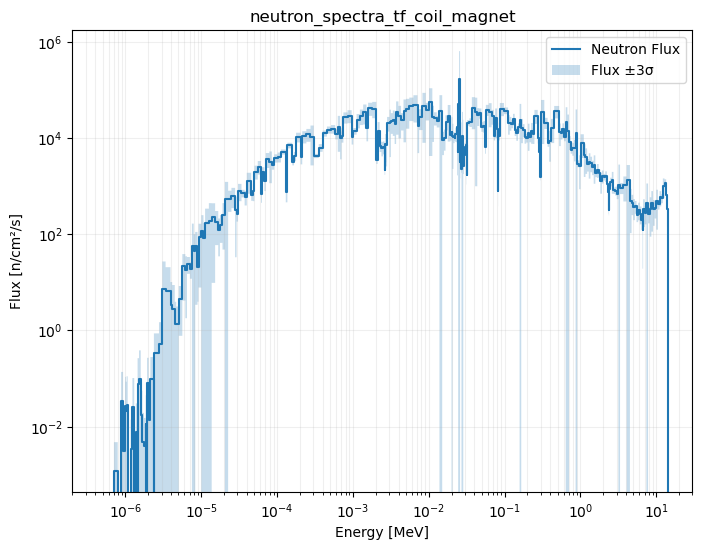

Total flux        = 2.747e+06 ± 1.682e+05 n/cm²/s (6.12 %)
Flux > 7 MeV      = 7.632e+03 ± 3.668e+02 n/cm²/s (4.81 %)
Flux 1–7 MeV      = 5.812e+04 ± 2.241e+03 n/cm²/s (3.86 %)
Flux < 1 MeV      = 2.681e+06 ± 1.681e+05 n/cm²/s (6.27 %)


In [10]:
plot_flux_spectrum(
    sp,
    name='neutron_spectra_tf_coil_magnet',
    volume=tf_coil_magnet_volume*1e6,
    number_of_neutrons_per_second=number_of_neutrons_per_second
)

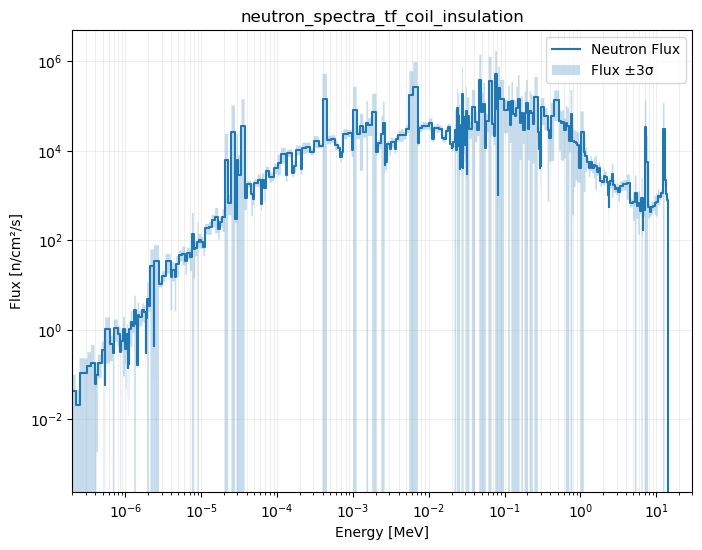

Total flux        = 7.464e+06 ± 7.818e+05 n/cm²/s (10.47 %)
Flux > 7 MeV      = 8.067e+04 ± 4.385e+04 n/cm²/s (54.36 %)
Flux 1–7 MeV      = 1.177e+05 ± 1.670e+04 n/cm²/s (14.19 %)
Flux < 1 MeV      = 7.265e+06 ± 7.804e+05 n/cm²/s (10.74 %)


In [11]:
plot_flux_spectrum(
    sp,
    name='neutron_spectra_tf_coil_insulation',
    volume=tf_coil_insulation_volume*1e6,
    number_of_neutrons_per_second=number_of_neutrons_per_second
)

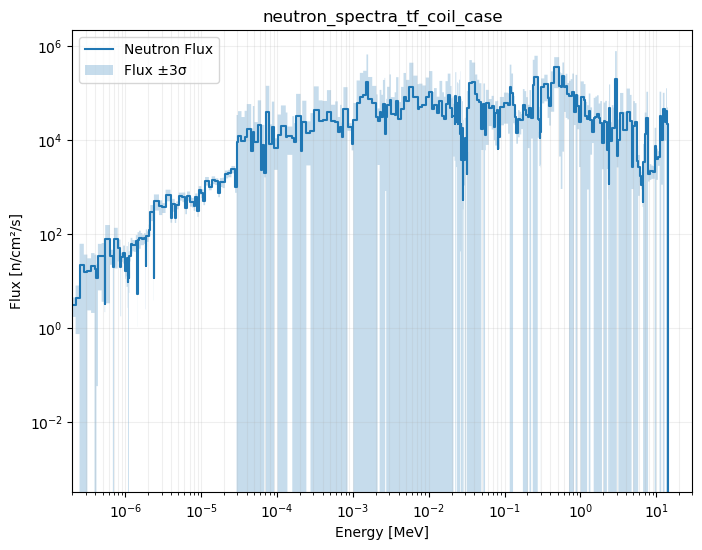

Total flux        = 9.674e+06 ± 5.220e+05 n/cm²/s (5.40 %)
Flux > 7 MeV      = 2.439e+05 ± 5.175e+04 n/cm²/s (21.22 %)
Flux 1–7 MeV      = 1.034e+06 ± 2.152e+05 n/cm²/s (20.82 %)
Flux < 1 MeV      = 8.397e+06 ± 4.727e+05 n/cm²/s (5.63 %)


In [12]:
plot_flux_spectrum(
    sp,
    name='neutron_spectra_tf_coil_case',
    volume=tf_coil_case_volume*1e6,
    number_of_neutrons_per_second=number_of_neutrons_per_second
)

## DPA

In [13]:
dpa_ybco_tally = sp.get_tally(name="dpa_ybco")
df_dpa_ybco = dpa_ybco_tally.get_pandas_dataframe()


damage_energy_in_eV = df_dpa_ybco['mean'].sum()
print('Damage energy deposited in YBCO per source neutron = ', damage_energy_in_eV, 'eV/source')

damage_energy_std = np.sqrt((df_dpa_ybco['std. dev.'] ** 2).sum()) ####

print('Two times the threshold energy of 40 eV is needed to displace an atom')
displacement_per_source_neutron = damage_energy_in_eV / (2 * 40)
print('Displacements per source neutron = ', displacement_per_source_neutron, 'eV/source')

print('Assuming 80% remanins after 20% recombine to original lattice locations')
displacements_per_source_neutron_with_recombination = displacement_per_source_neutron * 0.8
print('Displacements per source neutron after recombination = ', displacements_per_source_neutron_with_recombination, '\n')

number_of_neutrons_per_year = number_of_neutrons_per_second * 60 * 60 * 24 * 365.25
print('Number of neutrons per full power year ', number_of_neutrons_per_year)

displacements_for_all_atoms = number_of_neutrons_per_year * displacements_per_source_neutron_with_recombination
print('Displacements for all atoms in the volume ', displacements_for_all_atoms, '\n')

print('Now the number of atoms in the volume must be found to find displacements per atom (DPA)')

ybco_atomic_mass_in_g = 33.9 * 1.66054e-24

density_of_ybco_in_g_per_cm3 = 6.3

number_of_ybco_atoms = ybco_volume * density_of_ybco_in_g_per_cm3 / (ybco_atomic_mass_in_g)

print('Number of atoms on YBCO tape', number_of_ybco_atoms, '\n')

DPA = displacements_for_all_atoms / number_of_ybco_atoms
DPA_relative_error_percent = 100 * damage_energy_std / abs(damage_energy_in_eV) ####
DPA_std = abs(DPA) * DPA_relative_error_percent / 100 ####

print('DPA@10years =', DPA*10)
print(f'DPA = {DPA:.4e} ± {DPA_std:.2e}')
print(f'Errore relativo = {DPA_relative_error_percent:.2f}% (1σ)')

for target_mDPA in [1, 4]:
    days = (target_mDPA * 1e-3 / DPA) * 365.25
    print(f'{target_mDPA} mdpa after {days:.2f} days at full power')
for target_mDPA in [1, 4]:
    years = target_mDPA * 1e-3 / DPA
    print(f'{target_mDPA} mdpa after {years:.4f} years at full power')

Damage energy deposited in YBCO per source neutron =  0.95902093503663 eV/source
Two times the threshold energy of 40 eV is needed to displace an atom
Displacements per source neutron =  0.011987761687957874 eV/source
Assuming 80% remanins after 20% recombine to original lattice locations
Displacements per source neutron after recombination =  0.0095902093503663 

Number of neutrons per full power year  5.840863979461146e+27
Displacements for all atoms in the volume  5.6015108350046e+25 

Now the number of atoms in the volume must be found to find displacements per atom (DPA)
Number of atoms on YBCO tape 3.776144544513775e+26 

DPA@10years = 1.4833941786319684
DPA = 1.4834e-01 ± 8.30e-03
Errore relativo = 5.59% (1σ)
1 mdpa after 2.46 days at full power
4 mdpa after 9.85 days at full power
1 mdpa after 0.0067 years at full power
4 mdpa after 0.0270 years at full power
